原始记录数： 120108
有效地震记录数： 118360
选出的地震数： 50
入选震级范围： 6.5 ～ 8.2
震级最大的前 5 次地震：
                   time  mag  latitude  longitude                                   place
2014-04-01 23:46:47.260  8.2  -19.6097   -70.7691               94km NW of Iquique, Chile
2014-06-23 20:53:09.700  7.9   51.8486   178.7352 19km SE of Little Sitkin Island, Alaska
2014-04-03 02:43:13.110  7.7  -20.5709   -70.4931               53km SW of Iquique, Chile
2014-04-12 20:14:39.300  7.6  -11.2701   162.1481   93km SSE of Kirakira, Solomon Islands
2014-04-19 13:28:00.810  7.5   -6.7547   155.0241    70km SW of Panguna, Papua New Guinea


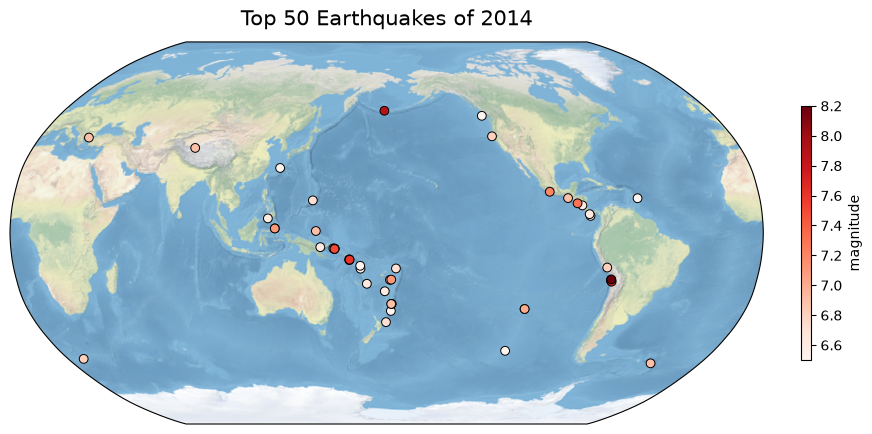

In [2]:
# 作业1：Global Earthquakes

import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# 读取数据同时将time列转换为日期时间类型，方便后面筛选年份
df = pd.read_csv("usgs_earthquakes.csv", parse_dates=["time"])
# 筛选2014年的地震
earthquakes = df[(df["time"].dt.year == 2014) & (df["type"] == "earthquake")]
# 将震级或经纬度缺失的记录筛掉
earthquakes = earthquakes.dropna(subset=["mag", "latitude", "longitude"])
# 在mag列中选出震级最大的50次地震 
top50 = earthquakes.nlargest(50, "mag", keep="first")

print("原始记录数：", len(df))
print("有效地震记录数：", len(earthquakes))
print("选出的地震数：", len(top50))
print("入选震级范围：", top50["mag"].min(), "～", top50["mag"].max())
print("震级最大的前 5 次地震：")
print(top50[["time", "mag", "latitude", "longitude", "place"]].head(5).to_string(index=False))

# 创建全球地图
fig = plt.figure(figsize=(12, 6))
# Robinson投影的外形接近参考图
# 通过central_longitude=180将太平洋放在地图中央
ax = fig.add_subplot(1, 1, 1,projection=ccrs.Robinson(central_longitude=180))
# 显示全球范围，并添加Cartopy自带的地形背景
ax.set_global()   
ax.stock_img()    
# 先画较小震级，再画较大震级，这样位置重叠时，较大震级的点会显示在上层
plot_data = top50.sort_values("mag")

# 绘制地震Top50散点图
points = ax.scatter(
    plot_data["longitude"],     
    plot_data["latitude"],      
    c=plot_data["mag"],         # 颜色由 mag 列决定
    cmap="Reds",                # 震级越大，颜色越红
    vmin=top50["mag"].min(),    # 色标下限
    vmax=top50["mag"].max(),    # 色标上限
    s=40,                      # 所有点使用相同面积
    edgecolors="black",        # 黑色边框
    linewidths=0.7,
    transform=ccrs.PlateCarree(),  # 输入坐标是普通经纬度
    zorder=3                   # 将散点显示在背景图上方
)
# 添加标题和图例色标
ax.set_title("Top 50 Earthquakes of 2014", fontsize=15, pad=12)

# 将散点的颜色与右侧色标关联起来
colorbar = fig.colorbar(points,ax=ax,orientation="vertical",shrink=0.55,pad=0.04,aspect=25)
colorbar.set_label("magnitude")
colorbar.set_ticks([6.6, 6.8, 7.0, 7.2, 7.4, 7.6, 7.8, 8.0, 8.2])

plt.show()